------------------------------
### Logistics & Supply Chain Analysis
------------------------------


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

FILE_PATH = "DataCoSupplyChainDataset.csv"

# The dataset is sometimes provided as a tab-separated file despite its .csv extension.
try:
    df = pd.read_csv(FILE_PATH, encoding="latin1", low_memory=False)
    if df.shape[1] == 1:
        df = pd.read_csv(FILE_PATH, sep="\t", encoding="latin1", low_memory=False)
except UnicodeDecodeError:
    df = pd.read_csv(FILE_PATH, encoding="latin1", low_memory=False)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully.
Rows: 180519
Columns: 53


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


### 1. Understand the data
#### Check column names, data types, duplicate rows, and missing values before making changes.

In [5]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
display(df.info())

print("\nDescriptive statistics (numeric columns):")
display(df.describe().T)

print("\nDescriptive statistics (all columns):")
display(df.describe(include="all").T)

print("\nDuplicate rows:", df.duplicated().sum())

missing = df.isna().sum().sort_values(ascending=False)
missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2)
})
display(missing_table[missing_table["missing_count"] > 0])

Dataset shape: (180519, 53)

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price',

None


Descriptive statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933



Descriptive statistics (all columns):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,180519,4,DEBIT,69295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days for shipping (real),180519.0,NaN,NaN,NaN,3.497654,1.623722,0.0,2.0,3.0,5.0,6.0
Days for shipment (scheduled),180519.0,NaN,NaN,NaN,2.931847,1.374449,0.0,2.0,4.0,4.0,4.0
Benefit per order,180519.0,NaN,NaN,NaN,21.974989,104.433526,-4274.97998,7.0,31.52,64.800003,911.799988
Sales per customer,180519.0,NaN,NaN,NaN,183.107609,120.04367,7.49,104.379997,163.990005,247.399994,1939.98999
Delivery Status,180519,4,Late delivery,98977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Late_delivery_risk,180519.0,NaN,NaN,NaN,0.548291,0.497664,0.0,0.0,1.0,1.0,1.0
Category Id,180519.0,NaN,NaN,NaN,31.851451,15.640064,2.0,18.0,29.0,45.0,76.0
Category Name,180519,50,Cleats,24551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer City,180519,563,Caguas,66770,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Duplicate rows: 0


,missing_count,missing_percent
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


### 2. Clean column names and duplicate rows
#### Column names are standardized for easier coding. Exact duplicate rows are removed.

In [6]:
clean_df = df.copy()

# Make column names consistent, while keeping their meaning.
clean_df.columns = (
    clean_df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

rows_before = len(clean_df)
clean_df = clean_df.drop_duplicates().copy()
duplicates_removed = rows_before - len(clean_df)

print("Duplicate rows removed:", duplicates_removed)
print("Rows after duplicate removal:", len(clean_df))

Duplicate rows removed: 0
Rows after duplicate removal: 180519


### 3. Fix data types and inspect dates
#### The original DataCo file commonly includes order_date_dateorders and shipping_date_dateorders. This cell converts date-like columns when they exist. It also converts common numeric columns safely.

In [7]:
# Convert likely date columns, if present.
date_columns = [c for c in clean_df.columns if "date" in c]
for col in date_columns:
    clean_df[col] = pd.to_datetime(clean_df[col], errors="coerce")

# Convert common numeric fields when present.
numeric_candidates = [
    "days_for_shipping_real", "days_for_shipment_scheduled",
    "benefit_per_order", "sales_per_customer", "late_delivery_risk",
    "order_item_discount", "order_item_discount_rate",
    "order_item_product_price", "order_item_profit_ratio",
    "order_item_quantity", "sales", "order_item_total",
    "order_profit_per_order", "product_price", "customer_zipcode",
    "latitude", "longitude"
]
for col in numeric_candidates:
    if col in clean_df.columns:
        clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

print("Date columns checked:", date_columns)
display(clean_df.dtypes.to_frame("data_type"))

Date columns checked: ['order_date_dateorders', 'shipping_date_dateorders']


,data_type
type,str
days_for_shipping_real,int64
days_for_shipment_scheduled,int64
benefit_per_order,float64
sales_per_customer,float64
delivery_status,str
late_delivery_risk,int64
category_id,int64
category_name,str
customer_city,str


### 4. Handle missing values
#### First review missingness. Numeric columns are filled with their median, while text/category columns use the most frequent value or Unknown. Date columns are left missing because guessing a date can create false information.

In [8]:
missing_before = clean_df.isna().sum()

for col in clean_df.columns:
    if clean_df[col].isna().any():
        if pd.api.types.is_datetime64_any_dtype(clean_df[col]):
            # Do not invent dates.
            continue
        elif pd.api.types.is_numeric_dtype(clean_df[col]):
            median_value = clean_df[col].median()
            if pd.notna(median_value):
                clean_df[col] = clean_df[col].fillna(median_value)
        else:
            mode_values = clean_df[col].mode(dropna=True)
            fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
            clean_df[col] = clean_df[col].fillna(fill_value)

missing_after = clean_df.isna().sum()
missing_summary = pd.DataFrame({
    "missing_before": missing_before,
    "missing_after": missing_after
})
display(missing_summary[missing_summary["missing_before"] > 0].sort_values("missing_before", ascending=False))
print("Remaining missing values:", int(clean_df.isna().sum().sum()))
print("Note: date fields with missing/invalid values remain missing rather than being guessed.")

,missing_before,missing_after
product_description,180519,180519
order_zipcode,155679,0
customer_lname,8,0
customer_zipcode,3,0


Remaining missing values: 180519
Note: date fields with missing/invalid values remain missing rather than being guessed.


### 5. Detect outliers using the IQR method
#### The IQR rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. For this exercise, outliers are capped at those limits for selected numeric measures, rather than deleting complete shipments/orders. Keep the original dataset if you need to investigate unusual real-world cases.

In [9]:
# Select numeric measures where extreme values may affect summary plots.
outlier_candidates = [
    "sales", "order_item_total", "order_item_product_price",
    "order_item_discount", "order_profit_per_order",
    "benefit_per_order", "days_for_shipping_real",
    "days_for_shipment_scheduled", "order_item_quantity"
]
outlier_columns = [c for c in outlier_candidates if c in clean_df.columns]

outlier_rows = []
for col in outlier_columns:
    # Ignore columns with no variation.
    q1 = clean_df[col].quantile(0.25)
    q3 = clean_df[col].quantile(0.75)
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        outlier_rows.append({"column": col, "lower_bound": q1, "upper_bound": q3,
                             "outliers_before": 0, "outliers_capped": 0})
        continue
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (clean_df[col] < lower) | (clean_df[col] > upper)
    count = int(mask.sum())
    clean_df[col] = clean_df[col].clip(lower=lower, upper=upper)
    outlier_rows.append({"column": col, "lower_bound": round(lower, 3),
                         "upper_bound": round(upper, 3),
                         "outliers_before": count, "outliers_capped": count})

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
print("Important: IQR capping changes extreme values. Compare with the raw data before business decisions.")

,column,lower_bound,upper_bound,outliers_before,outliers_capped
0,sales,-149.975,569.905,488,488
1,order_item_total,-110.150,461.930,1943,1943
2,order_item_product_price,-174.985,424.975,2048,2048
3,order_item_discount,-31.485,66.875,7537,7537
4,order_profit_per_order,-79.700,151.500,18942,18942
5,benefit_per_order,-79.700,151.500,18942,18942
6,days_for_shipping_real,-2.500,9.500,0,0
7,days_for_shipment_scheduled,-1.000,7.000,0,0
8,order_item_quantity,-2.000,6.000,0,0


Important: IQR capping changes extreme values. Compare with the raw data before business decisions.


### 6. Create useful logistics features
#### here available, calculate delivery delay and order month. These features support logistics-focused analysis.

In [10]:
if {"days_for_shipping_real", "days_for_shipment_scheduled"}.issubset(clean_df.columns):
    clean_df["delivery_delay_days"] = (
        clean_df["days_for_shipping_real"] - clean_df["days_for_shipment_scheduled"]
    )
    clean_df["late_delivery_flag"] = (clean_df["delivery_delay_days"] > 0).astype("Int64")

# Find an order-date column after column-name standardization.
order_date_col = next((c for c in clean_df.columns if "order_date" in c), None)
if order_date_col:
    clean_df["order_month"] = clean_df[order_date_col].dt.to_period("M").astype(str)

display(clean_df.head())

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_email,customer_fname,customer_id,customer_lname,customer_password,customer_segment,customer_state,customer_street,customer_zipcode,department_id,department_name,latitude,longitude,market,order_city,order_country,order_customer_id,order_date_dateorders,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,order_zipcode,product_card_id,product_category_id,product_description,product_image,product_name,product_price,product_status,shipping_date_dateorders,shipping_mode,delivery_delay_days,late_delivery_flag,order_month
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,-1,0,2018-01
1,TRANSFER,5,4,-79.700005,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-79.700005,South Asia,Rajastán,PENDING,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,1,1,2018-01
2,CASH,4,4,-79.700005,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-79.700005,South Asia,Rajastán,CLOSED,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,0,0,2018-01
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,-1,0,2018-01
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,-2,0,2018-01


### 7. Exploratory Data Analysis (EDA)
#### Plots are created only when the relevant columns exist, so the notebook is easier to reuse with similar logistics datasets.

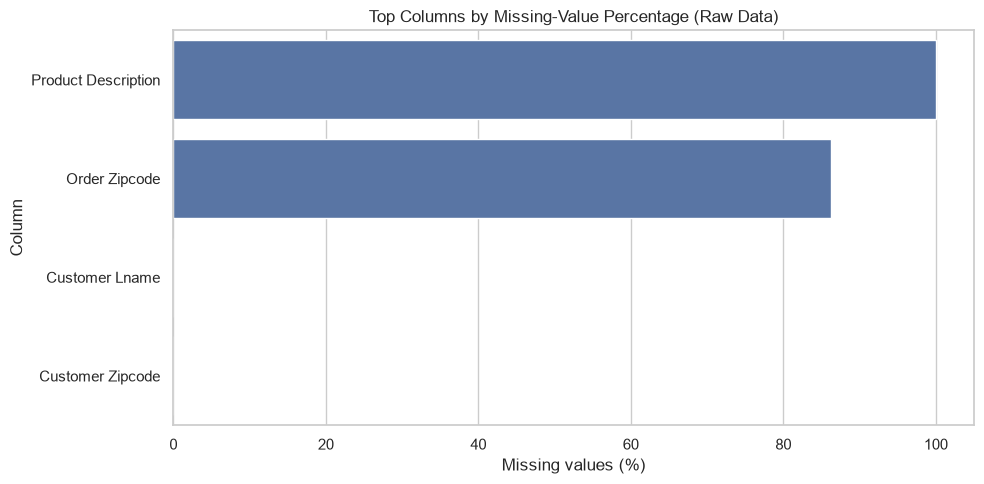

In [11]:
# A. Missing values before cleaning
missing_plot = (df.isna().mean() * 100).sort_values(ascending=False)
missing_plot = missing_plot[missing_plot > 0].head(20)
if not missing_plot.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing_plot.values, y=missing_plot.index)
    plt.xlabel("Missing values (%)")
    plt.ylabel("Column")
    plt.title("Top Columns by Missing-Value Percentage (Raw Data)")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the raw dataset.")

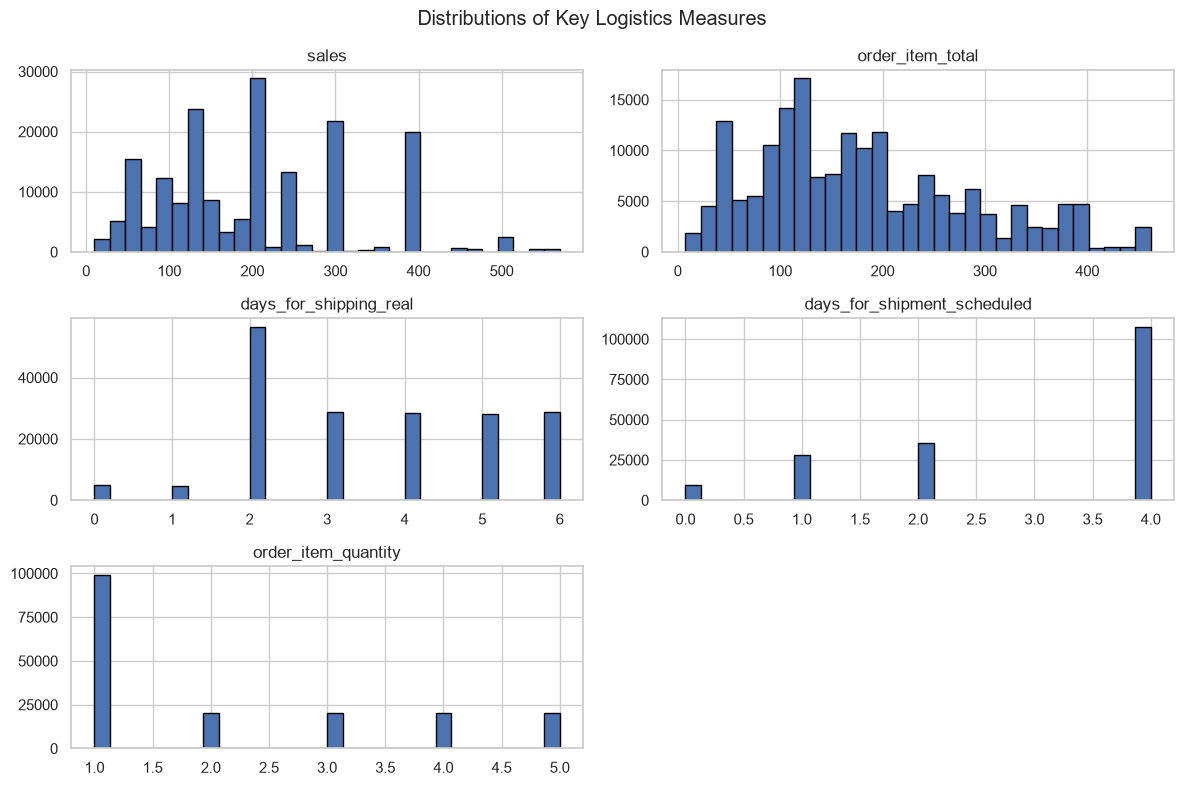

In [12]:
# B. Histograms for selected numeric fields
hist_cols = [c for c in ["sales", "order_item_total", "days_for_shipping_real",
                         "days_for_shipment_scheduled", "order_item_quantity"]
             if c in clean_df.columns]
if hist_cols:
    clean_df[hist_cols].hist(figsize=(12, 8), bins=30, edgecolor="black")
    plt.suptitle("Distributions of Key Logistics Measures")
    plt.tight_layout()
    plt.show()
else:
    print("No selected numeric columns available for histograms.")

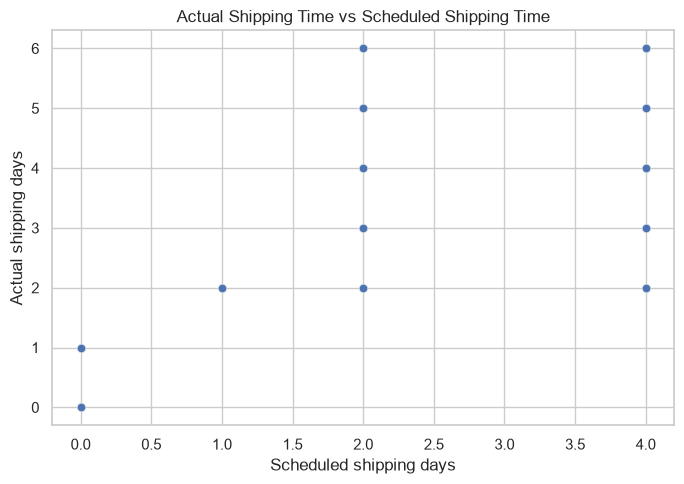

In [13]:
# C. Delivery performance: actual vs scheduled shipping days
if {"days_for_shipping_real", "days_for_shipment_scheduled"}.issubset(clean_df.columns):
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=clean_df.sample(min(len(clean_df), 5000), random_state=42),
                    x="days_for_shipment_scheduled",
                    y="days_for_shipping_real",
                    alpha=0.4)
    plt.title("Actual Shipping Time vs Scheduled Shipping Time")
    plt.xlabel("Scheduled shipping days")
    plt.ylabel("Actual shipping days")
    plt.tight_layout()
    plt.show()
else:
    print("Actual/scheduled shipping columns not found.")

,average_late_delivery_risk
shipping_mode,
First Class,0.953225
Second Class,0.766328
Same Day,0.457430
Standard Class,0.380717


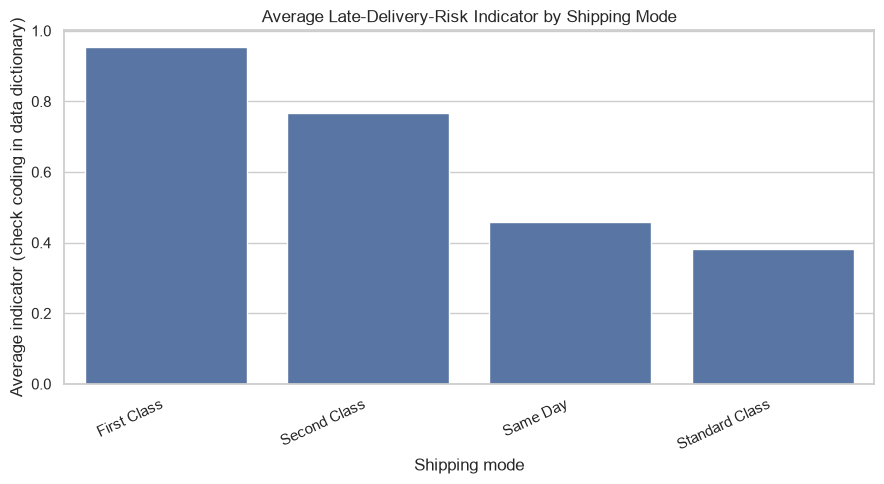

In [14]:
# D. Late delivery by shipping mode
if {"shipping_mode", "late_delivery_risk"}.issubset(clean_df.columns):
    mode_summary = clean_df.groupby("shipping_mode", dropna=False)["late_delivery_risk"].mean().sort_values(ascending=False)
    display(mode_summary.rename("average_late_delivery_risk").to_frame())
    plt.figure(figsize=(9, 5))
    sns.barplot(x=mode_summary.index, y=mode_summary.values)
    plt.title("Average Late-Delivery-Risk Indicator by Shipping Mode")
    plt.xlabel("Shipping mode")
    plt.ylabel("Average indicator (check coding in data dictionary)")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
elif {"shipping_mode", "late_delivery_flag"}.issubset(clean_df.columns):
    mode_summary = clean_df.groupby("shipping_mode")["late_delivery_flag"].mean().sort_values(ascending=False)
    display(mode_summary.rename("share_late_deliveries").to_frame())
    plt.figure(figsize=(9, 5))
    sns.barplot(x=mode_summary.index, y=mode_summary.values)
    plt.title("Share of Late Deliveries by Shipping Mode")
    plt.ylabel("Share of rows late")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Shipping mode / late-delivery fields not found.")

,total_sales
order_region,
Western Europe,5.691209e+06
Central America,5.665712e+06
South America,2.960881e+06
Northern Europe,2.079333e+06
Oceania,2.006423e+06
Southern Europe,1.975671e+06
Southeast Asia,1.899942e+06
Caribbean,1.651019e+06
West of USA,1.571416e+06


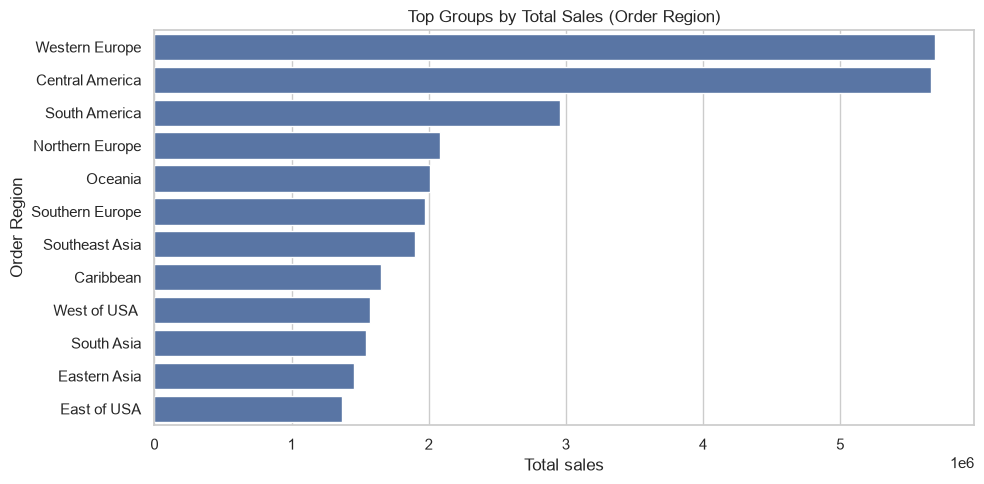

In [15]:
# E. Sales by market or region
group_col = next((c for c in ["order_region", "market", "order_country"] if c in clean_df.columns), None)
if group_col and "sales" in clean_df.columns:
    sales_by_group = clean_df.groupby(group_col)["sales"].sum().sort_values(ascending=False).head(12)
    display(sales_by_group.rename("total_sales").to_frame())
    plt.figure(figsize=(10, 5))
    sns.barplot(x=sales_by_group.values, y=sales_by_group.index)
    plt.title(f"Top Groups by Total Sales ({group_col.replace('_', ' ').title()})")
    plt.xlabel("Total sales")
    plt.ylabel(group_col.replace("_", " ").title())
    plt.tight_layout()
    plt.show()
else:
    print("Sales and region/market columns not both available.")

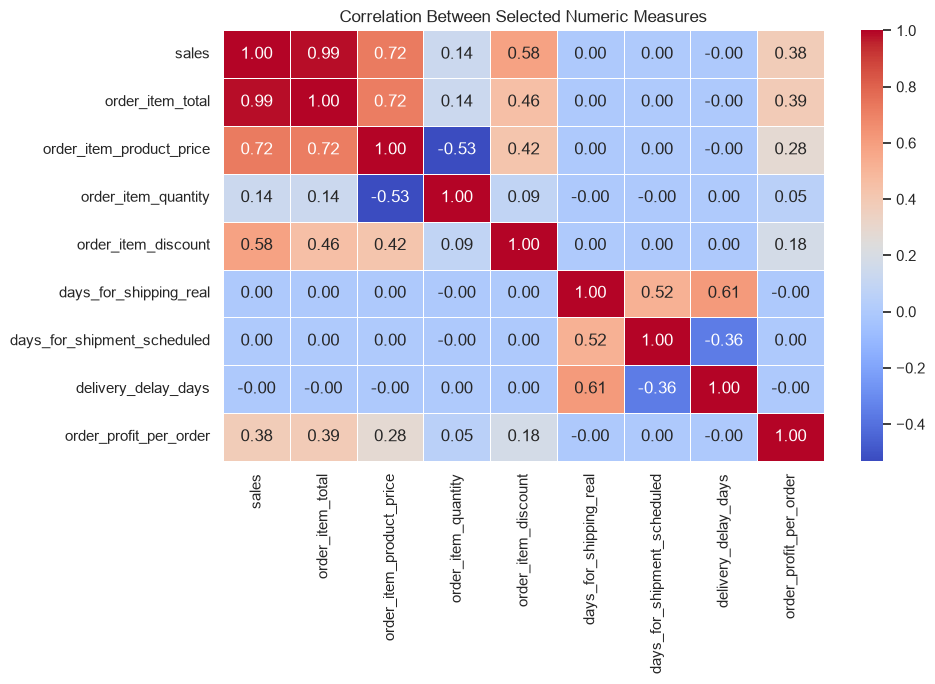

In [16]:
# F. Correlation heatmap for selected numeric columns
corr_cols = [c for c in ["sales", "order_item_total", "order_item_product_price",
                         "order_item_quantity", "order_item_discount",
                         "days_for_shipping_real", "days_for_shipment_scheduled",
                         "delivery_delay_days", "order_profit_per_order"]
             if c in clean_df.columns]
if len(corr_cols) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(clean_df[corr_cols].corr(numeric_only=True), annot=True, cmap="coolwarm",
                fmt=".2f", linewidths=0.5)
    plt.title("Correlation Between Selected Numeric Measures")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough selected numeric columns for a correlation heatmap.")

### 8. Summarize findings from the actual data
#### This cell creates a small summary that you can use in your report. Read the values and plots before making conclusions.

In [17]:
print("===== DATA QUALITY SUMMARY =====")
print(f"Raw rows: {df.shape[0]:,}")
print(f"Raw columns: {df.shape[1]:,}")
print(f"Exact duplicate rows removed: {duplicates_removed:,}")
print(f"Missing cells remaining after cleaning: {int(clean_df.isna().sum().sum()):,}")
print(f"Rows in cleaned data: {len(clean_df):,}")

if "delivery_delay_days" in clean_df.columns:
    print("\nDelivery delay (actual - scheduled days):")
    print(clean_df["delivery_delay_days"].describe())
    print("Rows later than schedule:", int((clean_df["delivery_delay_days"] > 0).sum()))
    print("Rows on or before schedule:", int((clean_df["delivery_delay_days"] <= 0).sum()))

if "sales" in clean_df.columns:
    print("\nSales summary:")
    print(clean_df["sales"].describe())

print("\nColumns with missing values remaining:")
display(clean_df.isna().sum()[clean_df.isna().sum() > 0].sort_values(ascending=False).to_frame("missing_count"))

===== DATA QUALITY SUMMARY =====
Raw rows: 180,519
Raw columns: 53
Exact duplicate rows removed: 0
Missing cells remaining after cleaning: 180,519
Rows in cleaned data: 180,519

Delivery delay (actual - scheduled days):
count    180519.000000
mean          0.565807
std           1.490966
min          -2.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: delivery_delay_days, dtype: float64
Rows later than schedule: 103400
Rows on or before schedule: 77119

Sales summary:
count    180519.000000
mean        201.348607
std         115.832661
min           9.990000
25%         119.980003
50%         199.919998
75%         299.950012
max         569.905025
Name: sales, dtype: float64

Columns with missing values remaining:


,missing_count
product_description,180519


### 9. Export the cleaned dataset and summaries
#### The output files are saved in the current notebook folder.

In [18]:
clean_df.to_csv("dataco_cleaned.csv", index=False)
missing_summary.to_csv("missing_value_summary.csv")
outlier_summary.to_csv("outlier_summary.csv", index=False)

print("Saved: dataco_cleaned.csv")
print("Saved: missing_value_summary.csv")
print("Saved: outlier_summary.csv")

Saved: dataco_cleaned.csv
Saved: missing_value_summary.csv
Saved: outlier_summary.csv


### 10. Report writing checklist
When you write the final findings, include:
- Raw row and column counts.
- Number of duplicate rows removed.
- Missing-value counts before and after cleaning.
- Which numeric columns were imputed with medians.
- Which categorical columns were filled with the mode or Unknown.
- IQR outlier counts and the selected columns capped.
- The main patterns seen in the delivery-time, shipping-mode, sales, and correlation plots.
- Limitations: this is a simulated dataset; outlier capping is a modelling choice; a row-level dataset may not equal unique shipments or orders.